<a href="https://colab.research.google.com/github/chaimae8-lang/PyTorch-Deep-Learning-Bootcamp/blob/main/PyTorch-Core-Supervised-Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# REGRESSION

In [ ]:
import torch

# Check for GPU access with PyTorch
print(torch.cuda.is_available())
print(torch.__version__)

# Count a number of devices
torch.cuda.device_count()

False
2.11.0+cpu


0

PYTORCH WORKFLOW

In [ ]:
from torch import nn # nn contains all of Pytorch building blocks for neural network
import matplotlib.pyplot as plt

1) Data (preparing and loading)

In [ ]:
weight = 0.7
bias = 0.3
X = torch.arange(0, 1, 0.02).unsqueeze(dim=1)
y = weight * X + bias
X.shape, y.shape

(torch.Size([50, 1]), torch.Size([50, 1]))

In [ ]:
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]
len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

/tmp/ipykernel_15402/207623300.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


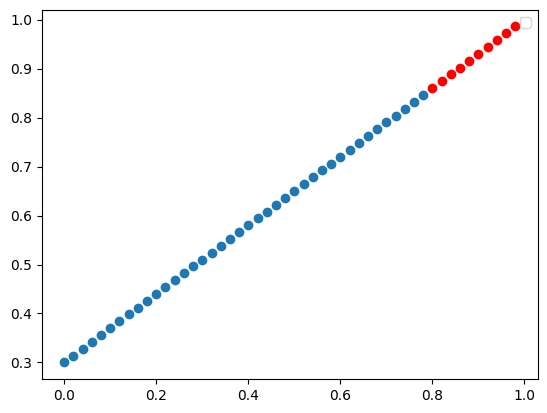

In [ ]:
plt.scatter(X_train, y_train)
plt.scatter(X_test, y_test, c='r')
plt.legend()

2) Build a Pytorch model

In [ ]:
class LinearRegressionModel(nn.Module):
  # Base class for all neural network modules. Your models should also subclass this class.
  def __init__(self):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float)) # Tensor.requires_grad: Is True if gradients need to be computed for this Tensor, False otherwise.
    self.bias = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float))

  def forward(self, x:torch.Tensor) -> torch.Tensor:
     return self.weights * x + self.bias

In [ ]:
torch.manual_seed(42)
model_0 = LinearRegressionModel()
print(model_0.parameters())
list(model_0.parameters())

<generator object Module.parameters at 0x795403c3b840>


[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
# List name parameters
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

3) Make predictions with model

In [ ]:
# This configuration deactivates training-specific layers like Dropout and freezes gradient tracking
with torch.inference_mode():
  y_pred_inf = model_0(X_test)

y_pred_inf

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

In [ ]:
y_pred = model_0(X_test)
y_pred

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]], grad_fn=<AddBackward0>)

PREDICTIONS PLOT FUNCTION

In [ ]:
def plot_predictions(preds):
  plt.scatter(X_train, y_train, label='Training data')
  plt.scatter(X_test, y_test, c='r', label="Testing data")
  plt.scatter(X_test, preds, label="Predictions")
  plt.legend()

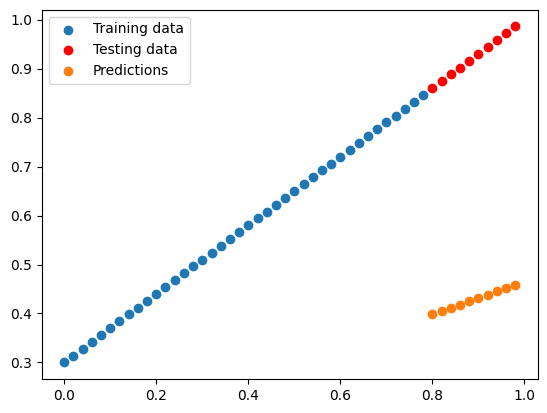

In [ ]:
plot_predictions(y_pred_inf)

In [ ]:
model_0 = LinearRegressionModel()

loss_f = nn.L1Loss()
optimizer = torch.optim.SGD(model_0.parameters(), lr=0.01)

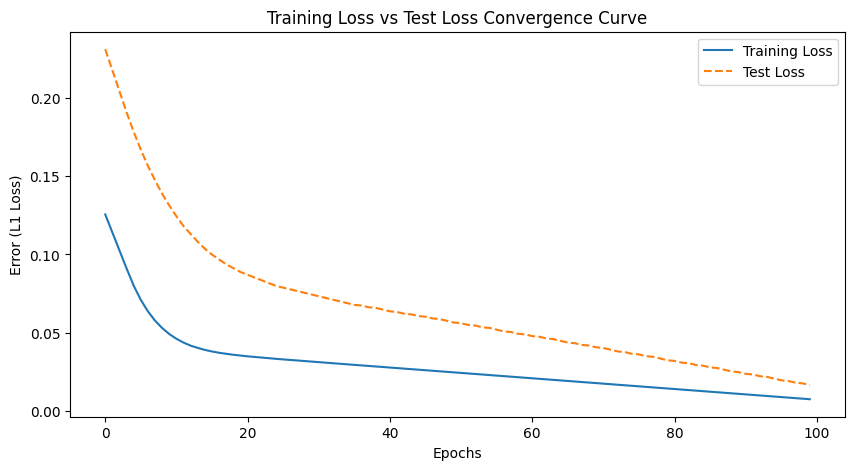

In [ ]:
# --- Initial Configuration & Hyperparameters ---
epochs = 100
training_loss_history = []
test_loss_history = []

# --- Main Optimization Loop ---
for epoch in range(epochs):

    # ==================== PHASE 1: TRAINING ====================
    # Set the model to training mode (activates dropout/batch norm layers)
    model_0.train()

    # Step A: Reset parameter gradients to zero before the next forward pass
    optimizer.zero_grad()

    # Step B: Execute Forward Pass on training data to generate predictions
    y_pred = model_0(X_train)

    # Step C: Compute training loss metric
    loss = loss_f(y_pred, y_train)

    # Extract raw scalar value using .item() to save VRAM and track history
    training_loss_history.append(loss.item())

    # Step D: Execute Backpropagation to compute parameter gradients
    loss.backward()

    # Step E: Update model parameters using the chosen optimizer step formula
    optimizer.step()

    # ==================== PHASE 2: TESTING / EVALUATION ====================
    # Switch the model to evaluation mode (deactivates dropout/batch norm)
    model_0.eval()

    # Open inference context manager to disable gradient tracking and optimize speed
    with torch.inference_mode():

        # Step F: Generate predictions on unseen test features
        test_pred = model_0(X_test)

        # Step G: Calculate test loss against ground truth targets (y_test)
        test_loss = loss_f(test_pred, y_test)

        # Extract scalar value to log test performance per epoch
        test_loss_history.append(test_loss.item())

# ==================== PHASE 3: CONVERGENCE PLOTTING ====================
plt.figure(figsize=(10, 5))
plt.plot(training_loss_history, label="Training Loss")
plt.plot(test_loss_history, label="Test Loss", linestyle="--")
plt.title("Training Loss vs Test Loss Convergence Curve")
plt.xlabel("Epochs")
plt.ylabel("Error (L1 Loss)")
plt.legend()
plt.show()

The .detach() method unlinks the tensor from the computational graph but keeps the object as a PyTorch tensor in memory. For tracking a scalar loss history, .item() is preferred because it converts the value into a native Python primitive, completely freeing GPU memory and preventing accumulated memory overhead across epochs.

Why we should use "zero_grad"?

By default, PyTorch accumulates and sums up gradients in the .grad variable during every backpropagation pass. The optimizer.zero_grad() command is therefore mathematically mandatory at the beginning of each iteration to reset these counters to zero, preventing gradient explosion and ensuring that weight updates are solely derived from the current step's data

TESTING

We can think of model.eval() as a strict checkpoint separating the training environment from the testing phase. This command freezes the behavior of dynamic layers like Dropout, ensuring the model transitions from an exploratory learning state to a pure, deterministic, and stable prediction mode.

In [ ]:
print(model_0.state_dict())

OrderedDict({'weights': tensor([0.6648]), 'bias': tensor([0.3149])})


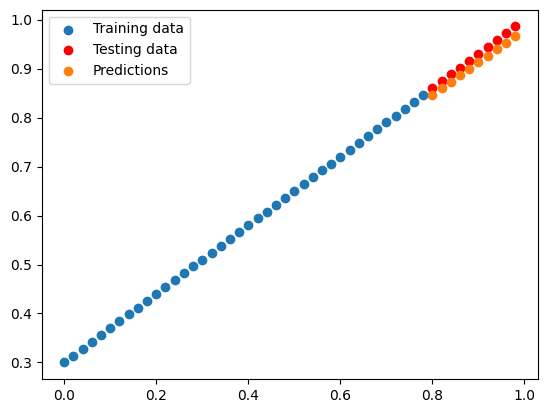

In [ ]:
with torch.inference_mode():
  y_preds_new = model_0(X_test)

plot_predictions(y_preds_new)

**==== SAVING A MODEL IN PYTORCH* ===*



In [ ]:
from pathlib import Path

# Create models directory
model_path = Path('models')
model_path.mkdir(parents=True, exist_ok=True)

# Save File
model_name = "O1_Pytorch_Workflow_model_0.pth"
model_save_path = model_path / model_name

# Save the model state dict
print(f"Saving model weights to: {model_save_path}")
torch.save(obj=model_0.state_dict(), f=model_save_path)

Saving model weights to: models/O1_Pytorch_Workflow_model_0.pth


**=== LOADING A PYTORCH MODEL ===**

In [ ]:
# Instatiate our model
loaded_model_0 = LinearRegressionModel()
print("Before loading : ", loaded_model_0.state_dict())

loaded_model_0.load_state_dict(torch.load(f=model_save_path))
print("After loading : ", loaded_model_0.state_dict())

Before loading :  OrderedDict({'weights': tensor([0.5349]), 'bias': tensor([0.8094])})
After loading :  OrderedDict({'weights': tensor([0.6648]), 'bias': tensor([0.3149])})


The loaded_model.load_state_dict(torch.load(...)) instruction combines two successive actions: torch.load deserializes the binary file from the disk to restore the trained dictionary of tensors, while load_state_dict maps and injects these numerical values into the corresponding parameters of a freshly instantiated architecture, enforcing strict structural shape matching.

# CREATE device_agnostic_code

To accelerate computations in PyTorch, we implement device-agnostic code by verifying torch.cuda.is_available(). It is then mathematically and computationally mandatory to transfer both the model architecture and the input data tensors onto the same device target using the .to(device) method to avoid cross-device memory fragmentation and runtime errors in VRAM.

Using device: cpu


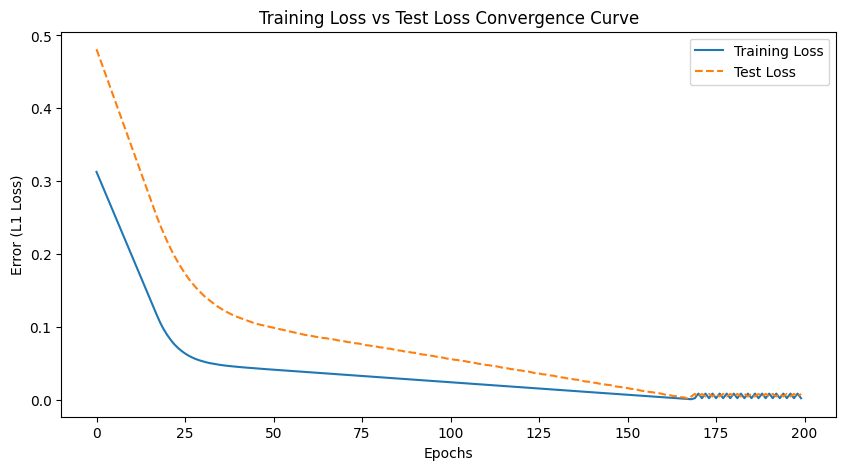

In [ ]:
# Define device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Instantiate the neural network architecture
model_0 = LinearRegressionModel()

# CRUCIAL: Transfer all model layers and parameters (nn.Parameter) to the selected device (VRAM/RAM)
model_0.to(device)

# Configure the loss function and optimization algorithm
loss_f = nn.L1Loss()
optimizer = torch.optim.SGD(model_0.parameters(), lr=0.01)

# Put the data on the device
X_train_device = X_train.to(device)
y_train_device = y_train.to(device)
X_test_device = X_test.to(device)
y_test_device = y_test.to(device)

# Put our model on the device
model_0.to(device)

torch.manual_seed(42)
epochs = 200
training_loss_history = []
test_loss_history = []

# --- Main Optimization Loop ---
for epoch in range(epochs):

    # ==================== PHASE 1: TRAINING ====================
    # Set the model to training mode (activates dropout/batch norm layers)
    model_0.train()

    # Step A: Reset parameter gradients to zero before the next forward pass
    optimizer.zero_grad()

    # Step B: Execute Forward Pass on training data to generate predictions
    y_pred = model_0(X_train_device)

    # Step C: Compute training loss metric
    loss = loss_f(y_pred, y_train_device)

    # Extract raw scalar value using .item() to save VRAM and track history
    training_loss_history.append(loss.item())

    # Step D: Execute Backpropagation to compute parameter gradients
    loss.backward()

    # Step E: Update model parameters using the chosen optimizer step formula
    optimizer.step()

    # ==================== PHASE 2: TESTING / EVALUATION ====================
    # Switch the model to evaluation mode (deactivates dropout/batch norm)
    model_0.eval()

    # Open inference context manager to disable gradient tracking and optimize speed
    with torch.inference_mode():

        # Step F: Generate predictions on unseen test features
        test_pred = model_0(X_test_device)

        # Step G: Calculate test loss against ground truth targets (y_test)
        test_loss = loss_f(test_pred, y_test_device)

        # Extract scalar value to log test performance per epoch
        test_loss_history.append(test_loss.item())

# ==================== PHASE 3: CONVERGENCE PLOTTING ====================
plt.figure(figsize=(10, 5))
plt.plot(training_loss_history, label="Training Loss")
plt.plot(test_loss_history, label="Test Loss", linestyle="--")
plt.title("Training Loss vs Test Loss Convergence Curve")
plt.xlabel("Epochs")
plt.ylabel("Error (L1 Loss)")
plt.legend()
plt.show()

# CLASSIFICATION : NEURAL NETWORK

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

In [ ]:
X, y = make_circles(1000, noise=0.03, random_state=42)
print("First 5 sample of X : ", X[:5])
print("First 5 sample of Y : ", y[:5])

First 5 sample of X :  [[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
First 5 sample of Y :  [1 1 1 1 0]


In [ ]:
# Make DataFrame of circle data
import pandas as pd
circles = pd.DataFrame({"X1": X[:, 0],
    "X2": X[:, 1],
    "label": y
})
circles.head(10)

,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


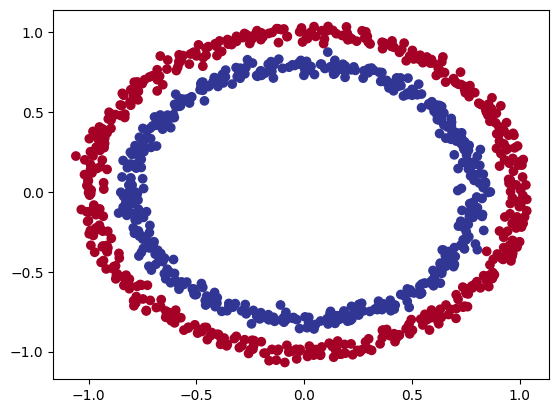

In [ ]:
# Visualize with a plot
import matplotlib.pyplot as plt
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)

In [ ]:
# Check input and output shapes
X.shape, y.shape

((1000, 2), (1000,))

Turn data into Tensors

In [ ]:
print("The type of X : ", type(X), X.dtype)
print("The type of Y : ", type(y), y.dtype)
X = torch.from_numpy(X).type(torch.float) # Convert dtype of X to float32 for Pytorch
y = torch.from_numpy(y).type(torch.float)

The type of X :  <class 'numpy.ndarray'> float64
The type of Y :  <class 'numpy.ndarray'> int64


In [ ]:
X[:5], y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [ ]:
from sklearn.model_selection import train_test_split

# Split data into training and test sets with the correct order of unpacking
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
#X_train_device = X_train.to(device)
#y_train_device

Create the model:
- With 2 nn.Linear() Layers

In [ ]:
class CircleModelV0(nn.Module):
  def __init__(self):
    super().__init__()
    self.network = nn.Sequential(
        nn.Linear(in_features=2, out_features=10),
        nn.ReLU(),
        nn.Linear(in_features=10, out_features=10),
        nn.ReLU(),
        nn.Linear(in_features=10, out_features=1)
    )

  def forward(self, x):
    return self.network(x)

In [ ]:
model_1 = CircleModelV0().to(device)
model_1

CircleModelV0(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=10, bias=True)
    (3): ReLU()
    (4): Linear(in_features=10, out_features=1, bias=True)
  )
)

In [ ]:
model_1.state_dict()

OrderedDict([('network.0.weight',
              tensor([[ 0.5614, -0.0746],
                      [ 0.1198,  0.1831],
                      [ 0.1756,  0.3058],
                      [-0.0614,  0.5286],
                      [-0.5046, -0.6035],
                      [-0.5207, -0.4138],
                      [-0.2332, -0.5414],
                      [-0.0383,  0.2724],
                      [-0.1493, -0.1273],
                      [ 0.2233, -0.3500]])),
             ('network.0.bias',
              tensor([-0.3645, -0.6199, -0.3236, -0.3381, -0.3419, -0.5586,  0.5362,  0.5501,
                      -0.6166,  0.5898])),
             ('network.2.weight',
              tensor([[-0.1434,  0.0126, -0.1887, -0.0932,  0.2820,  0.2968,  0.1103,  0.0487,
                        0.0994, -0.2648],
                      [ 0.1208, -0.0679, -0.2552, -0.0681,  0.2800,  0.2280,  0.2746,  0.2741,
                       -0.1300,  0.2481],
                      [ 0.1774,  0.1761, -0.2067, -0.2067,  0.2471

In [ ]:
X_train_dev = X_train.to(device)
y_train_dev = y_train.to(device)
X_test_dev = X_test.to(device)
y_test_dev = y_test.to(device)

**MAKE PREDICTIONS**

In [ ]:
# 1. Get raw scores (Logits) from the model
logits = model_1(X_test_dev)

# 2. Convert Logits to Probabilities using the Sigmoid function
probs = torch.sigmoid(logits)

# 3. Round probabilities to strict binary labels (0 or 1) and fix the shape
predicted_labels = torch.round(probs).squeeze()

predicted_labels == y_test_dev

tensor([ True, False,  True, False,  True,  True, False, False,  True, False,
        False,  True, False,  True, False,  True,  True, False,  True, False,
        False, False,  True, False, False, False, False, False, False,  True,
         True, False, False,  True, False,  True,  True,  True,  True,  True,
         True,  True,  True, False, False,  True, False, False,  True,  True,
        False, False, False, False,  True, False,  True,  True,  True, False,
         True, False, False,  True,  True,  True,  True, False, False, False,
         True, False, False,  True,  True,  True,  True, False, False,  True,
        False,  True, False,  True,  True,  True, False, False, False, False,
         True,  True,  True,  True,  True, False,  True,  True, False,  True,
        False, False,  True,  True, False, False,  True, False, False,  True,
         True,  True, False,  True,  True, False,  True, False,  True, False,
         True, False, False,  True,  True, False,  True,  True, 

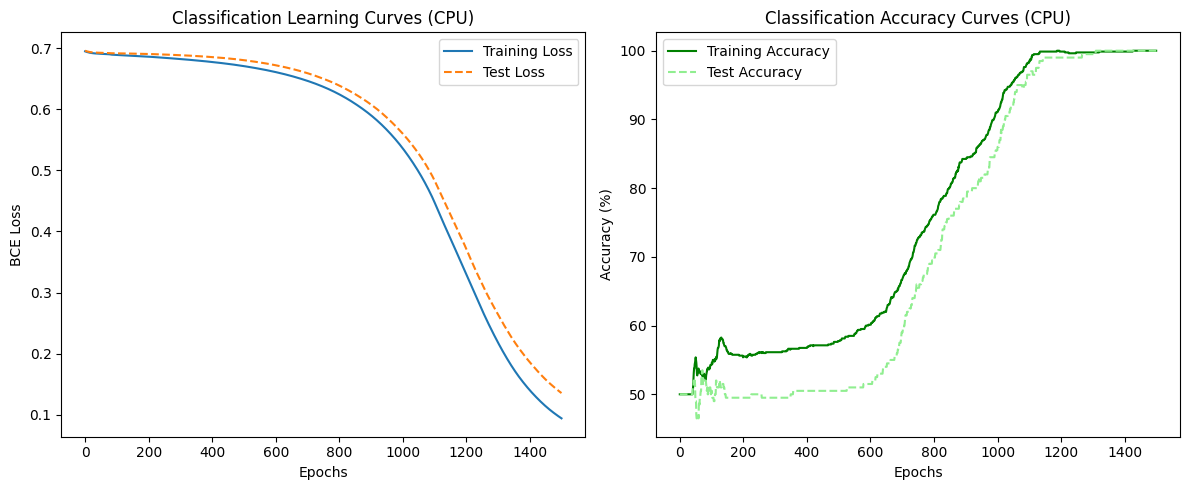

In [ ]:
model_1 = CircleModelV0().to(device)
# --- 1. ACCURACY METRIC FUNCTION ---
def accuracy_fn(y_true, y_pred):
    return (torch.eq(y_true, y_pred).sum().item() / len(y_true)) * 100

# --- 2. CONFIGURATION AND HYPERPARAMETERS ---
cross_loss = nn.BCEWithLogitsLoss()
classifier_optimizer = torch.optim.SGD(model_1.parameters(), lr=0.1)
epochs = 1500

# Lists to track loss history
training_closs_history = []
test_closs_history = []

# ADDED: Lists to track accuracy history
training_acc_history = []
test_acc_history = []

# --- 3. OPTIMIZATION LOOP ---
for epoch in range(epochs):
    # ==================== PHASE 1: TRAINING ====================
    model_1.train()
    classifier_optimizer.zero_grad()

    # Forward pass: extract raw scores (Logits)
    train_logist = model_1(X_train_dev).squeeze()

    # Compute and track training loss
    loss = cross_loss(train_logist, y_train_dev)
    training_closs_history.append(loss.item())

    # Calculate and track training accuracy
    train_preds = torch.round(torch.sigmoid(train_logist))
    acc = accuracy_fn(y_train_dev, train_preds)
    training_acc_history.append(acc) # ADDED

    # Execute backpropagation and optimization step
    loss.backward()
    classifier_optimizer.step()

    # ==================== PHASE 2: TESTING / EVALUATION ====================
    model_1.eval() # Boundary checkpoint active
    with torch.inference_mode():
        # Inference pass
        test_logist = model_1(X_test_dev).squeeze()

        # Compute and track test loss
        t_loss = cross_loss(test_logist, y_test_dev)
        test_closs_history.append(t_loss.item())

        # Calculate and track test accuracy
        test_preds = torch.round(torch.sigmoid(test_logist))
        test_acc = accuracy_fn(y_test_dev, test_preds)
        test_acc_history.append(test_acc) # ADDED

# ==================== PHASE 4: VISUALIZATION ====================
# Plot 1: Loss Curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1) # Create a subplot grid (1 row, 2 columns, active panel 1)
plt.plot(training_closs_history, label="Training Loss")
plt.plot(test_closs_history, label="Test Loss", linestyle="--")
plt.title(f"Classification Learning Curves ({device.upper()})")
plt.xlabel("Epochs")
plt.ylabel("BCE Loss")
plt.legend()

# ADDED: Plot 2: Accuracy Curves (active panel 2)
plt.subplot(1, 2, 2)
plt.plot(training_acc_history, label="Training Accuracy", color="green")
plt.plot(test_acc_history, label="Test Accuracy", linestyle="--", color="lightgreen")
plt.title(f"Classification Accuracy Curves ({device.upper()})")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout() # Adjust spacing automatically
plt.show()


import pytorch_lightning as pl

class LitCircleModel(pl.LightningModule):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(2, 10), nn.ReLU(), nn.Linear(10, 1))
        self.loss_fn = nn.BCEWithLogitsLoss()

    def training_step(self, batch, batch_idx):
        x, y = batch
        logits = self.network(x).squeeze()
        loss = self.loss_fn(logits, y)
        return loss

    def configure_optimizers(self):
        return torch.optim.SGD(self.parameters(), lr=0.1)

# L'entraînement automatique s'exécute en 2 lignes !
trainer = pl.Trainer(max_epochs=1000, accelerator="auto")
trainer.fit(model=LitCircleModel(), train_dataloaders=train_loader)


In [ ]:
import numpy as np

def plot_decision_boundary(model: nn.Module, X: torch.Tensor, y: torch.Tensor):
    """
    Plots a color-coded decision boundary generated by a PyTorch model.
    Brings data back to CPU if running on GPU.
    """
    # Move model and data back to CPU for NumPy/Matplotlib compatibility
    model.to("cpu")
    X, y = X.to("cpu"), y.to("cpu")

    # Setup prediction boundaries (min/max coordinates) with margins
    x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
    y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1

    # Generate grid coordinates
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 101),
                         np.linspace(y_min, y_max, 101))

    # Reshape grid into coordinate pairs for inference pass
    grid_tensors = torch.from_numpy(np.c_[xx.ravel(), yy.ravel()]).type(torch.float32)

    # Execute inference pass to get predictions
    model.eval()
    with torch.inference_mode():
        logits = model(grid_tensors).squeeze()
        # Convert logits to binary class predictions (0 or 1)
        preds = torch.round(torch.sigmoid(logits))

    # Reshape predictions back to grid format for contour plotting
    zz = preds.numpy().reshape(xx.shape)

    # Plot the color mesh background
    plt.contourf(xx, yy, zz, cmap=plt.cm.RdYlBu, alpha=0.8)
    # Overlay the original scatter data points
    plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.RdYlBu, edgecolors="k")
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())

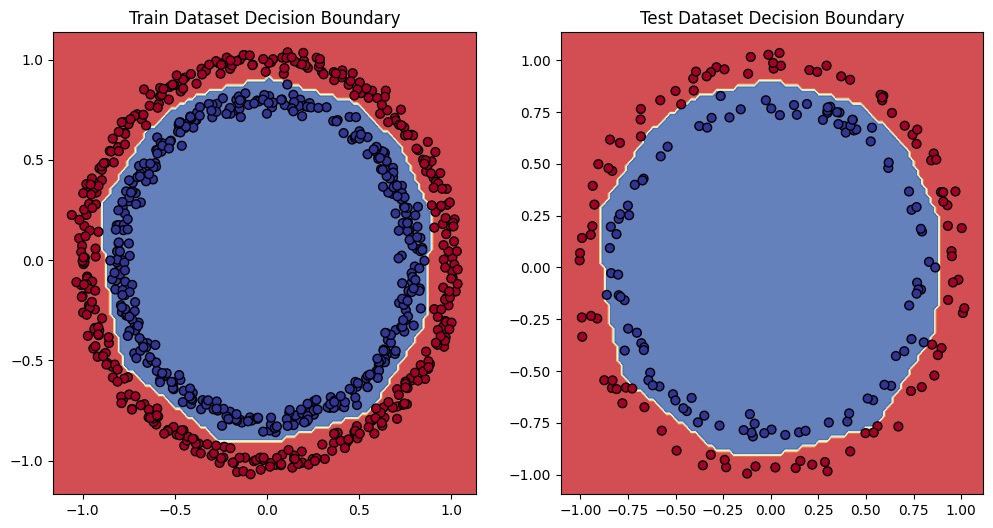

In [ ]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train Dataset Decision Boundary")
plot_decision_boundary(model_1, X_train_dev, y_train_dev)

plt.subplot(1, 2, 2)
plt.title("Test Dataset Decision Boundary")
plot_decision_boundary(model_1, X_test_dev, y_test_dev)
plt.show()

# MULTI-CLASSIFICATION

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

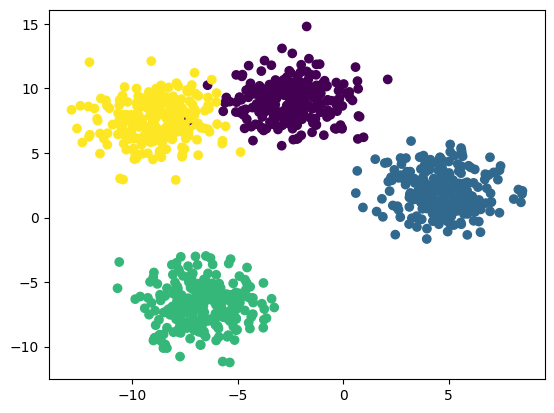

In [ ]:
X_blob, y_blob = make_blobs(n_samples=1000, n_features=2, centers=4, cluster_std=1.5, random_state=42) # centers : number of classes

X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)

X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob, y_blob, test_size=0.2, random_state=42)
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob)

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
class MultiClassClassification(nn.Module):
  def __init__(self):
     super().__init__()
     self.network = nn.Sequential(
         nn.Linear(in_features=2, out_features=10),
         nn.ReLU(),
         nn.Linear(in_features=10, out_features=10),
         nn.ReLU(),
         nn.Linear(in_features=10, out_features=4)
     )

  def forward(self, x):
    return self.network(x)

In [ ]:
model_mc = MultiClassClassification().to(device)
model_mc

MultiClassClassification(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=10, bias=True)
    (3): ReLU()
    (4): Linear(in_features=10, out_features=4, bias=True)
  )
)

In [ ]:
model_mc.state_dict()

OrderedDict([('network.0.weight',
              tensor([[ 0.3995,  0.1668],
                      [-0.2759, -0.5206],
                      [ 0.0016,  0.4256],
                      [-0.6015, -0.5057],
                      [ 0.2461,  0.4198],
                      [ 0.4205,  0.1919],
                      [-0.0428,  0.6405],
                      [ 0.1746, -0.5349],
                      [-0.0807, -0.3459],
                      [ 0.1953, -0.5590]])),
             ('network.0.bias',
              tensor([-0.6939,  0.2393, -0.6236,  0.5124, -0.1384,  0.0664,  0.4401, -0.4824,
                       0.0060, -0.0365])),
             ('network.2.weight',
              tensor([[-0.1305, -0.2399, -0.1867,  0.0135, -0.0962,  0.1558,  0.2915, -0.2613,
                       -0.0762, -0.1590],
                      [-0.0699, -0.0694, -0.1588, -0.0401,  0.0553, -0.2660,  0.2283, -0.0996,
                       -0.0718, -0.2610],
                      [ 0.1887,  0.2836,  0.3084,  0.0187,  0.2971

In [ ]:
X_blob_train_dev = X_blob_train.to(device)
y_blob_train_dev = y_blob_train.to(device)

X_blob_test_dev = X_blob_test.to(device)
y_blob_test_dev = y_blob_test.to(device)

MAKE PREDICTIONS

In [ ]:
logits = model_mc(X_blob_test_dev)
probs = torch.softmax(logits, dim=1)
label_preds = torch.argmax(probs, dim=1)
label_preds

tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1])

In [ ]:
loss_mc = nn.CrossEntropyLoss()
optimizer_mc = torch.optim.SGD(params=model_mc.parameters(), lr=0.1)

TRAINNING & TEST LOOP

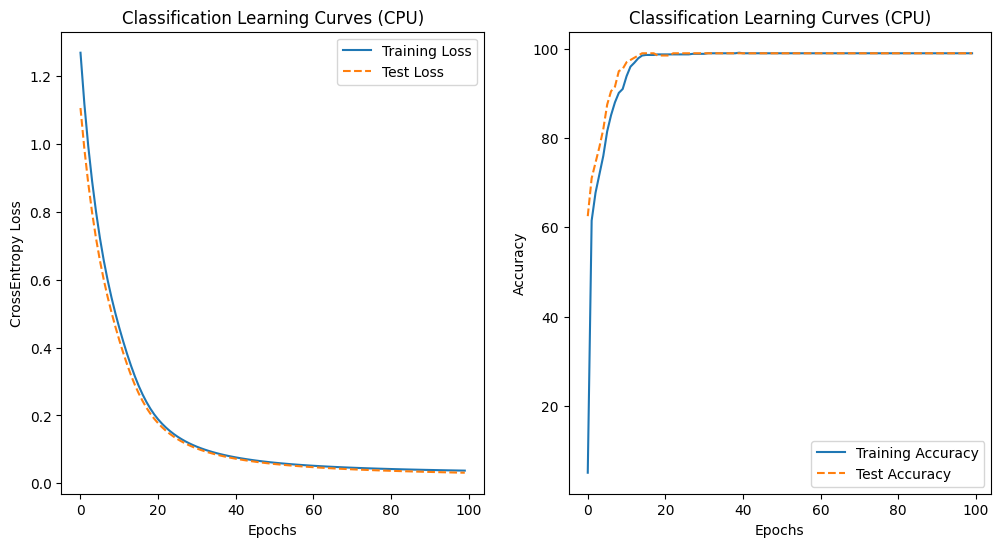

In [ ]:
model_mc = MultiClassClassification().to(device)
loss_mc = nn.CrossEntropyLoss()
optimizer_mc = torch.optim.SGD(params=model_mc.parameters(), lr=0.1)

def accuracy_mc(y_true, y_pred):
  return (torch.eq(y_true, y_pred).sum().item() / len(y_true) * 100)

loss_mc_train_hist = []
loss_mc_test_hist = []

accuracy_mc_train_hist = []
accuracy_mc_test_hist = []


epochs = 100

for epoch in range(epochs):
  # Train
  model_mc.train()

  # Set gradients at zero
  optimizer_mc.zero_grad()

  # Predictions and loss
  train_logist_mc = model_mc(X_blob_train_dev)
  loss = loss_mc(train_logist_mc, y_blob_train_dev)
  loss_mc_train_hist.append(loss.item())

  acc = accuracy_mc(y_true=y_blob_train_dev, y_pred=torch.argmax(torch.softmax(train_logist_mc, dim=1), dim=1))
  accuracy_mc_train_hist.append(acc)

  # Backward
  loss.backward()

  optimizer_mc.step()

  # Test
  model_mc.eval()
  with torch.inference_mode():
    test_logist_mc = model_mc(X_blob_test_dev)
    t_loss = loss_mc(test_logist_mc, y_blob_test_dev)
    loss_mc_test_hist.append(t_loss.item())

    t_acc = accuracy_mc(y_true=y_blob_test_dev, y_pred=torch.argmax(torch.softmax(test_logist_mc, dim=1), dim=1))
    accuracy_mc_test_hist.append(t_acc)

plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.plot(loss_mc_train_hist, label="Training Loss")
plt.plot(loss_mc_test_hist, label="Test Loss", linestyle="--")
plt.title(f"Classification Learning Curves ({device.upper()})")
plt.xlabel("Epochs")
plt.ylabel("CrossEntropy Loss")
plt.legend()

plt.subplot(122)
plt.plot(accuracy_mc_train_hist, label="Training Accuracy")
plt.plot(accuracy_mc_test_hist, label="Test Accuracy", linestyle="--")
plt.title(f"Classification Learning Curves ({device.upper()})")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 8.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [ ]:
from torchmetrics import Accuracy

# 1. On instancie la métrique en définissant la tâche (ici multiclasse avec 4 classes)
accuracy_metric = Accuracy(task="multiclass", num_classes=4).to(device)

# 2. On calcule l'exactitude en passant les prédictions et les vrais labels
preds = torch.argmax(torch.softmax(train_logist_mc, dim=1), dim=1)
accuracy_metric(preds, y_blob_train_dev)

tensor(0.9900)

<Figure size 1000x600 with 0 Axes>

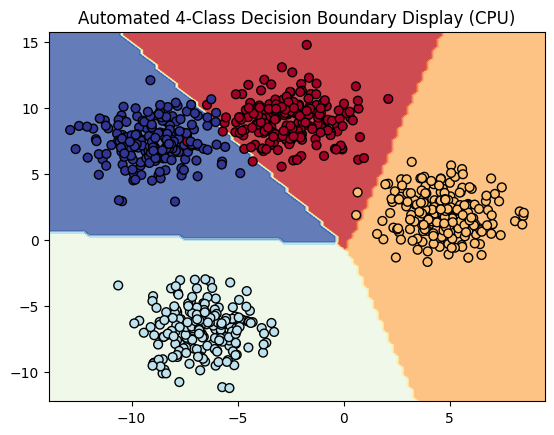

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.inspection import DecisionBoundaryDisplay

# ==================== 1. SCIKIT-LEARN COMPATIBLE ADAPTER ====================
class PyTorchEstimatorWrapper:
    def __init__(self, model, device):
        self.model = model
        self.device = device
        self._estimator_type = "classifier"
        self.classes_ = np.array([0, 1, 2, 3])

    def fit(self, X, y=None):
        # Le modèle est déjà entraîné en PyTorch
        return self

    def predict(self, X_numpy):
        # Convertit la grille d'entrée NumPy en tenseur PyTorch et l'envoie sur le périphérique
        X_tensor = torch.from_numpy(X_numpy).type(torch.float32).to(self.device)

        # Passage en mode évaluation
        self.model.eval()
        with torch.inference_mode():
            logits = self.model(X_tensor)
            preds = torch.argmax(logits, dim=1)

        return preds.cpu().numpy()

# Instanciation de l'adaptateur compatible scikit-learn
estimator_adapter = PyTorchEstimatorWrapper(model_mc, device)

# ==================== 2. AUTOMATED PLOTTING ====================
plt.figure(figsize=(10, 6))

# Génère automatiquement les frontières de décision à partir de l'adaptateur
DecisionBoundaryDisplay.from_estimator(
    estimator=estimator_adapter,
    X=X_blob_train.numpy(), # Caractéristiques de base pour définir les limites du graphique
    response_method="predict",
    cmap=plt.cm.RdYlBu,    # Palette de couleurs
    alpha=0.8
)

# Superpose les vrais points d'entraînement (rapatriés sur le CPU par sécurité)
plt.scatter(X_blob_train_dev.cpu()[:, 0], X_blob_train_dev.cpu()[:, 1],
            c=y_blob_train_dev.cpu(), s=40, cmap=plt.cm.RdYlBu, edgecolors="k")

plt.title(f"Automated 4-Class Decision Boundary Display ({device.upper()})")
plt.show()

To determine the linear separability of a dataset, we apply a dual validation protocol. In low-dimensional spaces, a visual exploratory analysis using scatter plots allows for checking the existence of straight decision hyperplanes. In high-dimensional spaces, we train a purely linear classifier as a baseline: a low evaluation score mathematically validates the necessity to transition towards a deep architecture embedding non-linear activations like ReLU.

# Automated MULTI CLASSIFICATION

In [ ]:
pip install skorch

  epoch    train_loss    valid_acc    valid_loss     dur
-------  ------------  -----------  ------------  ------
      1        0.7941       0.9688        0.5068  0.0291
      2        0.3875       0.9812        0.2467  0.0150
      3        0.1988       0.9812        0.1422  0.0143
      4        0.1267       0.9812        0.1010  0.0135
      5        0.0944       0.9812        0.0803  0.0155
      6        0.0769       0.9812        0.0680  0.0141
      7        0.0663       0.9812        0.0599  0.0131
      8        0.0591       0.9812        0.0542  0.0155
      9        0.0541       0.9812        0.0500  0.0144
     10        0.0503       0.9812        0.0469  0.0152
     11        0.0475       0.9812        0.0444  0.0176
     12        0.0452       0.9812        0.0424  0.0135
     13        0.0434       0.9812        0.0408  0.0217
     14        0.0419       0.9812        0.0395  0.0191
     15        0.0407       0.9812        0.0383  0.0139
     16        0.0397       0.9

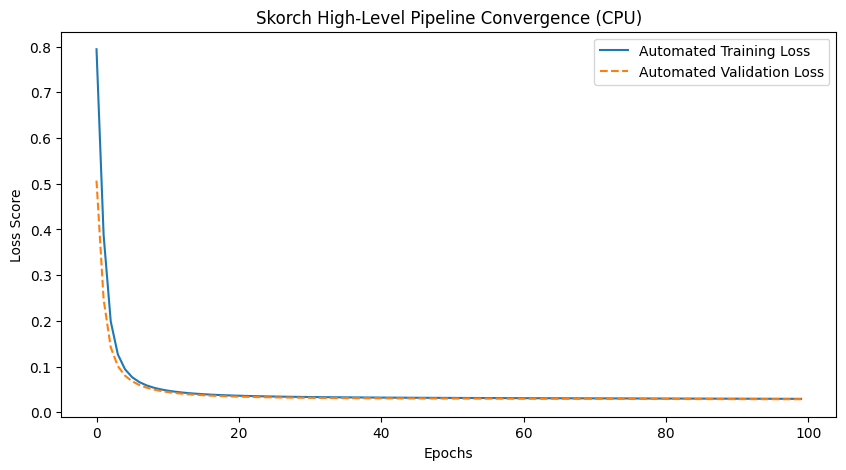

Final Automated Test Accuracy: 100.00%


In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from skorch import NeuralNetClassifier

# ==================== 1. DATA PREPARATION ====================
X_blob, y_blob = make_blobs(n_samples=1000, n_features=2, centers=4, cluster_std=1.5, random_state=42)

# RECTIFIED: Skorch requires standard float32 and int64 NumPy arrays as inputs [source: 1.2.2]
X_blob = X_blob.astype("float32")
y_blob = y_blob.astype("int64")

X_train, X_test, y_train, y_test = train_test_split(X_blob, y_blob, test_size=0.2, random_state=42)

device = "cuda" if torch.cuda.is_available() else "cpu"

# ==================== 2. PYTORCH ARCHITECTURE ====================
# We keep our standard PyTorch neural network structure
class MultiClassClassificationAutomated(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(in_features=2, out_features=10),
            nn.ReLU(),
            nn.Linear(in_features=10, out_features=10),
            nn.ReLU(),
            nn.Linear(in_features=10, out_features=4) # 4 classes output
        )
    def forward(self, x):
        return self.network(x)

# ==================== 3. AUTOMATED SKORCH TRAINER ====================
# Replaces the entire manual for-loop, zero_grad, backward, and step routines! [source: 1.2.2]
net = NeuralNetClassifier(
    module=MultiClassClassificationAutomated,    # Pass the PyTorch class architecture [source: 1.2.1]
    criterion=nn.CrossEntropyLoss,      # Predefined loss function [source: 1.2.1]
    optimizer=torch.optim.SGD,          # Predefined optimizer algorithm [source: 1.2.1]
    lr=0.1,                             # Learning rate hyperparameter [source: 1.2.1]
    max_epochs=100,                     # Number of training epochs [source: 1.2.1]
    device=device                       # Automated hardware deployment (CPU or GPU) [source: 1.2.1]
)

# LA LIGNE MAGIQUE : Déclenche l'intégralité de l'entraînement et du test automatiques [source: 1.2.2]
net.fit(X_train, y_train)

# ==================== 4. ANALYSIS AND PLOTTING ====================
# Skorch stores the entire training logs inside the net.history object [source: 1.2.2]
train_loss = net.history[:, 'train_loss']
valid_loss = net.history[:, 'valid_loss'] # Automatic validation split performed by Skorch [source: 1.2.8]

plt.figure(figsize=(10, 5))
plt.plot(train_loss, label="Automated Training Loss")
plt.plot(valid_loss, label="Automated Validation Loss", linestyle="--")
plt.title(f"Skorch High-Level Pipeline Convergence ({device.upper()})")
plt.xlabel("Epochs")
plt.ylabel("Loss Score")
plt.legend()
plt.show()

# Evaluate final Accuracy on unseen test data using Sklearn interface style [source: 1.2.2]
test_accuracy = net.score(X_test, y_test) * 100
print(f"Final Automated Test Accuracy: {test_accuracy:.2f}%")